<a href="https://colab.research.google.com/github/Aleksandrov-Vsevolod/dls_homeworks/blob/main/hw_1_game_of_thrones2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

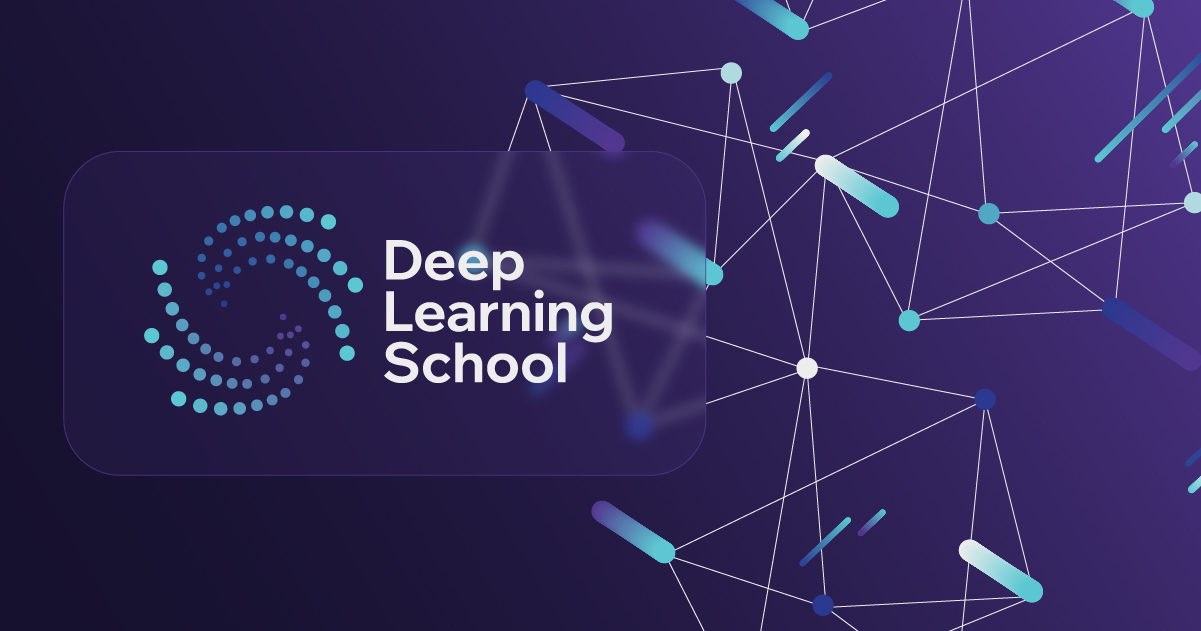

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

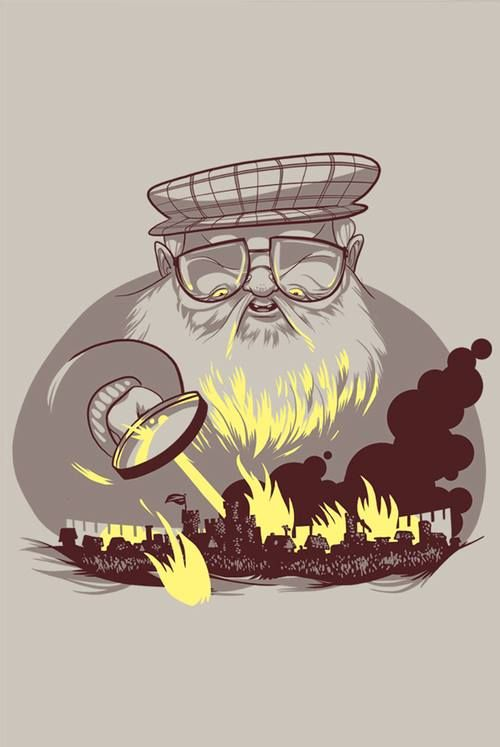

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [1]:
!gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
!gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

Downloading...
From: https://drive.google.com/uc?id=1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3
To: /content/game_of_thrones_test.csv
100% 37.3k/37.3k [00:00<00:00, 33.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v
To: /content/game_of_thrones_train.csv
100% 138k/138k [00:00<00:00, 5.49MB/s]


**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [3]:
data = pd.read_csv('/content/game_of_thrones_train.csv', index_col='S.No')

In [4]:
data

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity,isAlive
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,...,1.0,0.0,0.0,NaN,0,0,NaN,11,0.605351,0
2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,Perra Royce,...,NaN,NaN,NaN,1.0,1,1,97.0,1,0.896321,1
3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.267559,1
4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,...,NaN,NaN,NaN,0.0,1,1,23.0,0,0.183946,0
5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,Eldon Estermont,...,NaN,NaN,NaN,1.0,1,1,29.0,0,0.043478,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1553,Marwyn,Archmaester,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.160535,1
1554,Masha Heddle,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,0,NaN,0,0.040134,0
1555,Matthos Seaworth,NaN,1,NaN,NaN,NaN,NaN,NaN,House Seaworth,NaN,...,NaN,NaN,NaN,NaN,0,0,NaN,0,0.076923,0


Посмотрите, какие типы данных представлены в нашем датасете

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [5]:
data.describe(include = 'object').T

,count,unique,top,freq
name,1557,1557,Melara Hetherspoon,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              1557 non-null   object 
 1   title             717 non-null    object 
 2   male              1557 non-null   int64  
 3   culture           488 non-null    object 
 4   dateOfBirth       279 non-null    float64
 5   mother            18 non-null     object 
 6   father            22 non-null     object 
 7   heir              21 non-null     object 
 8   house             1176 non-null   object 
 9   spouse            200 non-null    object 
 10  book1             1557 non-null   int64  
 11  book2             1557 non-null   int64  
 12  book3             1557 non-null   int64  
 13  book4             1557 non-null   int64  
 14  book5             1557 non-null   int64  
 15  isAliveMother     18 non-null     float64
 16  isAliveFather     22 non-null     float64
 17  

In [7]:
data.describe(include = ['int64', 'float64']).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [8]:
data.isna().sum()

,0
name,0
title,840
male,0
culture,1069
dateOfBirth,1278
mother,1539
father,1535
heir,1536
house,381
spouse,1357


В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

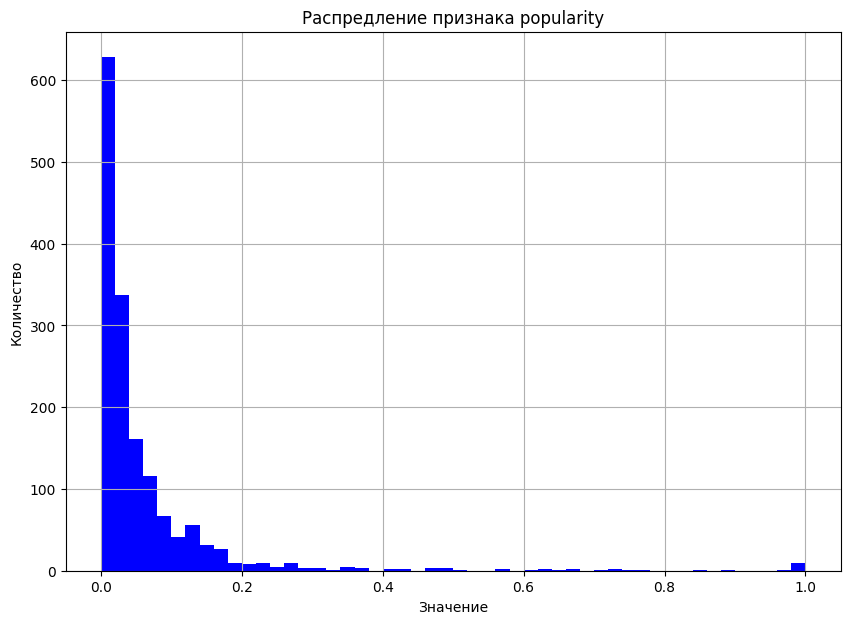

In [9]:
plt.figure(figsize=(10,7))
plt.hist(data['popularity'], bins=50, color='blue')

plt.title('Распредление признака popularity')

plt.xlabel('Значение')
plt.ylabel('Количество')

plt.grid()
plt.show()

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.


In [10]:
import numpy as np

In [11]:
M = 100
data["popularity"] = np.log10(data["popularity"]*M+1)

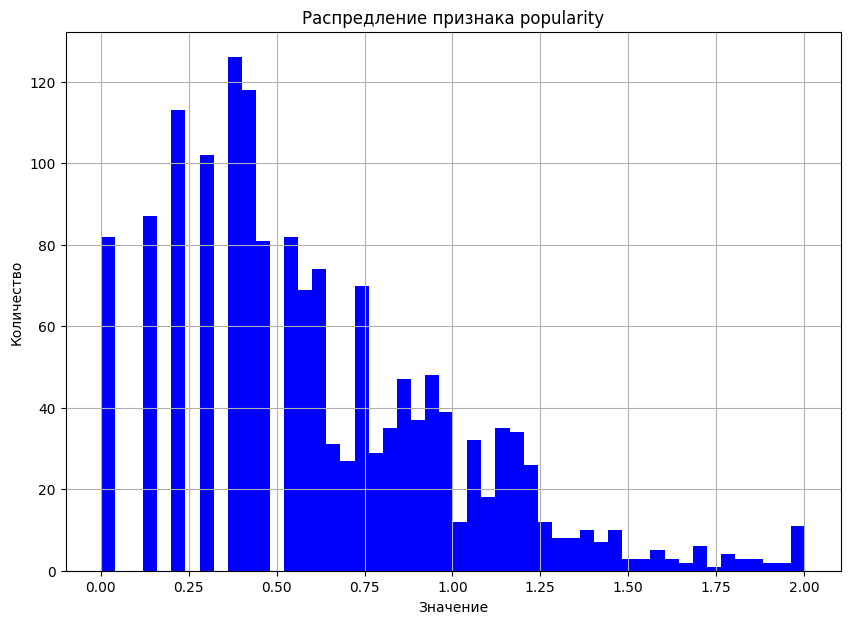

In [12]:
plt.figure(figsize=(10,7))
plt.hist(data['popularity'], bins=50, color='blue')

plt.title('Распредление признака popularity')

plt.xlabel('Значение')
plt.ylabel('Количество')

plt.grid()
plt.show()

В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

In [13]:
data['boolDeadRelations'] = data['numDeadRelations'] > 0

In [14]:
data['boolDeadRelations']

,boolDeadRelations
S.No,
1,True
2,True
3,False
4,False
5,False
...,...
1553,False
1554,False
1555,False


In [15]:
data['numDeadRelations']

,numDeadRelations
S.No,
1,11
2,1
3,0
4,0
5,0
...,...
1553,0
1554,0
1555,0


Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, age_value принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [16]:
data['age_value'] = [0 if np.isnan(x) else x for x in data['age']]
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]

In [17]:
data['age_value']

,age_value
S.No,
1,0.0
2,97.0
3,0.0
4,23.0
5,29.0
...,...
1553,0.0
1554,0.0
1555,0.0


In [18]:
data['age']

,age
S.No,
1,NaN
2,97.0
3,NaN
4,23.0
5,29.0
...,...
1553,NaN
1554,NaN
1555,NaN


Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [19]:
data['culture'].value_counts(dropna=False)

,count
culture,
NaN,1069
Northmen,94
Ironborn,91
Free Folk,45
Braavosi,39
Valyrian,28
Ghiscari,17
Dornish,17
Dothraki,17


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предоженный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не сущевали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [20]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [21]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [22]:
cultures_grouped_inverted = {}

for k in cultures_grouped.keys():
  for v in cultures_grouped[k]:
    cultures_grouped_inverted.update({v:k})

cultures_grouped_inverted

{'valyrian': 'Old Nations',
 'first men': 'Old Nations',
 'andal': 'Old Nations',
 'andals': 'Old Nations',
 'rhoynar': 'Old Nations',
 'northmen': 'the North',
 'northern mountain clans': 'the North',
 'crannogmen': 'the North',
 'ironborn': 'the Iron Islands',
 'ironmen': 'the Iron Islands',
 'valemen': 'the Mountain and the Vale',
 'vale': 'the Mountain and the Vale',
 'vale mountain clans': 'the Mountain and the Vale',
 'sistermen': 'the Mountain and the Vale',
 'riverlands': 'the Isles and Rivers',
 'rivermen': 'the Isles and Rivers',
 'westerman': 'the Rock',
 'westermen': 'the Rock',
 'westerlands': 'the Rock',
 'stormlander': 'the Stormlands',
 'stormlands': 'the Stormlands',
 'reach': 'the Reach',
 'reachmen': 'the Reach',
 'the reach': 'the Reach',
 'dornish': 'Dorne',
 'dornishmen': 'Dorne',
 'dorne': 'Dorne',
 'astapor': 'Essos Nations',
 'astapori': 'Essos Nations',
 'braavosi': 'Essos Nations',
 'braavos': 'Essos Nations',
 'tyroshi': 'Essos Nations',
 'lysene': 'Essos Na

Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [23]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [24]:
data['culture_grouped'] = ['culture_no_data' if pd.isna(x) else x for x in data['culture_grouped']]

In [25]:
data['culture_grouped']

,culture_grouped
S.No,
1,culture_no_data
2,the Isles and Rivers
3,culture_no_data
4,culture_no_data
5,Dorne
...,...
1553,culture_no_data
1554,culture_no_data
1555,culture_no_data


Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [26]:
# Количество уникальнх значений в каждом столбце
data.nunique()

,0
name,1557
title,195
male,2
culture,51
dateOfBirth,105
mother,16
father,19
heir,20
house,315
spouse,186


In [27]:
# Для числовых столбцов можно вывести в одну таблицу более детальную статистику, объединив выводы describe() и nunique()
# Код ниже требуется дополнить по аналогии с заданием 1.2.
data.describe(include = ['int64', 'float64']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.000000,2
dateOfBirth,279.0,-25.0,299.000000,105
book1,1557.0,0.0,1.000000,2
book2,1557.0,0.0,1.000000,2
book3,1557.0,0.0,1.000000,2
book4,1557.0,0.0,1.000000,2
book5,1557.0,0.0,1.000000,2
isAliveMother,18.0,0.0,1.000000,2
isAliveFather,22.0,0.0,1.000000,2
isAliveHeir,21.0,0.0,1.000000,2


In [28]:
data.columns

Index(['name', 'title', 'male', 'culture', 'dateOfBirth', 'mother', 'father',
       'heir', 'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5',
       'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse',
       'isMarried', 'isNoble', 'age', 'numDeadRelations', 'popularity',
       'isAlive', 'boolDeadRelations', 'age_value', 'age_no_data',
       'culture_grouped'],
      dtype='object')

Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [29]:
# попробуйте провести сравнение средних зависимой пременной isAlive для признака isAliveSpouse
# одним из приведенных ниже способов:

data.groupby('isAliveSpouse', dropna = False)['isAlive'].mean()
# pd.pivot_table(data = data, values = 'isAlive', index = 'isAliveSpouse', aggfunc=['mean', 'count'], dropna=False)

,isAlive
isAliveSpouse,
0.0,0.619048
1.0,0.753165
NaN,0.786293


**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

In [30]:
data.describe(include = ['int64', 'float64', 'object']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique(), N_nan=data.isna().sum(), dtype=data.dtypes)

,count,min,max,N_unique_values,N_nan,dtype
name,1557,NaN,NaN,1557,0,object
title,717,NaN,NaN,195,840,object
male,1557.0,0.0,1.0,2,0,int64
culture,488,NaN,NaN,51,1069,object
dateOfBirth,279.0,-25.0,299.0,105,1278,float64
mother,18,NaN,NaN,16,1539,object
father,22,NaN,NaN,19,1535,object
heir,21,NaN,NaN,20,1536,object
house,1176,NaN,NaN,315,381,object
spouse,200,NaN,NaN,186,1357,object


In [31]:
categorical_columns = [column for column in data.columns if data[column].dtype == 'O']
categorical_columns
# +бинарные male, isNoble, isMarried

['name',
 'title',
 'culture',
 'mother',
 'father',
 'heir',
 'house',
 'spouse',
 'culture_grouped']

Среди категориальных признаков, которые потенциально могут влиять на целевую переменную, я выделил: title, culture_grouped, house, isNoble, male, isMarried, isAliveSpouse, isMotherAlive, isFatherAlive

Обработка title

Из таблицы выше видно, что уникальных титулов - 195. Обрабатывать буду по следующему алгоритму: оставлю частые титулы, то есть те, которые встречаются более 10 раз, все остальное - в редкие. Но перед эти объединим похожие титулы, например 'King' и 'King of ...'


In [32]:
s = np.unique(data['title'].dropna().str.strip(), return_counts=True)
names, counts = s

s_new = [[names[0]], [counts[0]]]
title_grouped_inverted = {names[0]: names[0]}

for m in range(1, len(names)):
    base = s_new[0][-1]
    if counts[m] < 10 and names[m].startswith(base):
        s_new[1][-1] += counts[m]
        title_grouped_inverted[names[m]] = base
    else:
        s_new[0].append(names[m])
        s_new[1].append(counts[m])
        title_grouped_inverted[names[m]] = names[m]

s_new

[['Acorn Hall',
  'Archmaester',
  'Ashford',
  'Banefort',
  'Big BucketThe Wull',
  'Bitterbridge',
  'Blackcrown',
  'Blackmont',
  'Bloodrider',
  'Blue Grace',
  'Brightwater',
  'Broad Arch',
  'Brother',
  'Captain',
  'Castellan',
  'Casterly Rock',
  'Castle Lychester',
  'Cerwyn',
  'Chief Undergaoler',
  'Claw Isle',
  'Cobblecat',
  'Coldmoat',
  'Coldwater Burn',
  'Commander of the Second Sons',
  'Crag',
  'Crakehall',
  'Cupbearer',
  'Deepwood Motte',
  'Dragonstone',
  'Duskendale',
  'Dyre Den',
  'Eastwatch-by-the-Sea',
  'Eyrie',
  'Fair Isle',
  'Feastfires',
  'Felwood',
  'First Ranger',
  'First Sword of Braavos',
  'Foamdrinker',
  'Ghost Hill',
  'Godsgrace',
  'Golden Tooth',
  'Goldengrove',
  'Goldgrass',
  'Good Master',
  'Goodman',
  'Goodwife',
  'Grand Maester',
  'Grassy Vale',
  'Greenshield',
  'Greenstone',
  'Grey Glen',
  'Gulltown',
  'Hand of the King',
  'Harrenhal',
  'Harridan Hill',
  'Hayford',
  "Heart's Home",
  'High Steward of Highgar

Выше код, объединяющий титулы. s_new - двумерный массив без похожих титулов. title_grouped_inverted - словарь, аналогичный cultures_grouped_inverted. Теперь титулы, которые встречаются менее 10 раз нужно объединить в rare


In [33]:
s_new[0].append('rare')
s_new[1].append(0)

names, counts = s_new

for m in range(0, len(names)-1):
  if counts[m] < 10:
    counts[-1] += counts[m]
    names[m] = '-'
    counts[m] = 0

s_new

names_final = [x for x in names if x != '-']
counts_final = [x for x in counts if x != 0]

s_final = [names_final, counts_final]
s_final

[['Archmaester',
  'King',
  'Lady',
  'Lord',
  'Maester',
  'Prince',
  'Septon',
  'Ser',
  'Winterfell',
  'rare'],
 [np.int64(21),
  np.int64(18),
  np.int64(15),
  np.int64(64),
  np.int64(29),
  np.int64(26),
  np.int64(16),
  np.int64(307),
  np.int64(15),
  np.int64(206)]]

In [34]:
freq = set(names_final) - {'rare'}

title_final = {}
for orig, base in title_grouped_inverted.items():
    if base in freq:
        title_final[orig] = base
    else:
        title_final[orig] = 'rare'

title_final

{'Acorn Hall': 'rare',
 'Archmaester': 'Archmaester',
 'Ashford': 'rare',
 'Banefort': 'rare',
 'Big BucketThe Wull': 'rare',
 'Bitterbridge': 'rare',
 'Blackcrown': 'rare',
 'Blackmont': 'rare',
 'Bloodrider': 'rare',
 'Blue Grace': 'rare',
 'Brightwater': 'rare',
 'Broad Arch': 'rare',
 'Brother': 'rare',
 'BrotherProctor': 'rare',
 'Captain': 'rare',
 'Captain of the guard': 'rare',
 'Castellan': 'rare',
 'CastellanCommander': 'rare',
 'Casterly Rock': 'rare',
 'Castle Lychester': 'rare',
 'Cerwyn': 'rare',
 'Chief Undergaoler': 'rare',
 'Claw Isle': 'rare',
 'Cobblecat': 'rare',
 'Coldmoat': 'rare',
 'Coldwater Burn': 'rare',
 'Commander of the Second Sons': 'rare',
 'Crag': 'rare',
 'Crakehall': 'rare',
 'Cupbearer': 'rare',
 'Deepwood Motte': 'rare',
 'Dragonstone': 'rare',
 'Duskendale': 'rare',
 'Dyre Den': 'rare',
 'Eastwatch-by-the-Sea': 'rare',
 'Eyrie': 'rare',
 'Fair Isle': 'rare',
 'Feastfires': 'rare',
 'Felwood': 'rare',
 'First Ranger': 'rare',
 'First Sword of Braavos

Аналогично culture добавляем в датасет новый столбец: title_grouped

In [35]:
data['title_grouped'] = data['title'].map(title_final)
data['title_grouped'] = ['title_no_data' if pd.isna(x) else x for x in data['title_grouped']]
data['title_grouped']

,title_grouped
S.No,
1,title_no_data
2,Lord
3,Ser
4,rare
5,rare
...,...
1553,Archmaester
1554,title_no_data
1555,title_no_data


Обработка house

Видно, что большинство домов встречаются не более 10 раз, поэтому аналогично поделим дома на частые и редкие. Редкие вынесем в rare. Но в отличие от title здесь нет похожий названий

In [36]:
s = np.unique(data['house'].dropna().str.strip(), return_counts=True)

names, counts = s
names, counts = list(names), list(counts)

names.append('rare')
counts.append(0)

for m in range(0, len(names) - 1):
  if counts[m] < 10:
    names[m] = '-'
    counts[-1] += counts[m]
    counts[m] = 0

names_final = [x for x in names if x != '-']
counts_final = [x for x in counts if x != 0]

s_new = [names_final, counts_final]
s_new

[['Faith of the Seven',
  'House Arryn',
  'House Botley',
  'House Crakehall',
  'House Florent',
  'House Frey',
  'House Greyjoy',
  'House Hightower',
  'House Lannister',
  'House Martell',
  'House Osgrey',
  'House Stark',
  'House Targaryen',
  'House Tyrell',
  "Night's Watch",
  'rare'],
 [np.int64(15),
  np.int64(11),
  np.int64(12),
  np.int64(10),
  np.int64(10),
  np.int64(89),
  np.int64(30),
  np.int64(12),
  np.int64(36),
  np.int64(11),
  np.int64(20),
  np.int64(56),
  np.int64(40),
  np.int64(33),
  np.int64(88),
  np.int64(703)]]

Теперь на основе полученного s_new создадим словарь

In [37]:
freq = set(names_final) - {'rare'}

all_houses = data['house'].dropna().unique()

house_final = {h: (h if h in freq else 'rare') for h in all_houses}

house_final

{'House Frey': 'House Frey',
 'House Swyft': 'rare',
 'House Arryn': 'House Arryn',
 'House Santagar': 'rare',
 'House Targaryen': 'House Targaryen',
 'House Osgrey': 'House Osgrey',
 "Night's Watch": "Night's Watch",
 'House Humble': 'rare',
 'House Wylde': 'rare',
 'House Wode': 'rare',
 'House Fell': 'rare',
 'Brotherhood Without Banners': 'rare',
 'House Webber': 'rare',
 'House Greyjoy': 'House Greyjoy',
 'House Stark': 'House Stark',
 'House Waynwood': 'rare',
 'House Dayne': 'rare',
 'House Manderly': 'rare',
 'House Farwynd of the Lonely Light': 'rare',
 'Happy Port': 'rare',
 'House of Loraq': 'rare',
 'Kingswood Brotherhood': 'rare',
 'House Botley': 'House Botley',
 'Burned Men': 'rare',
 'House Velaryon': 'rare',
 'House Tallhart': 'rare',
 'House Tyrell': 'House Tyrell',
 'House Blackwood': 'rare',
 'House Blackfyre': 'rare',
 'wildling': 'rare',
 'Kingdom of the Three Daughters': 'rare',
 'House Royce of the Gates of the Moon': 'rare',
 'House Nayland': 'rare',
 "House Va

In [38]:
data['house_grouped'] = data['house'].map(house_final)
data['house_grouped'] = ['house_no_data' if pd.isna(x) else x for x in data['house_grouped']]
data['house_grouped']

,house_grouped
S.No,
1,house_no_data
2,House Frey
3,rare
4,House Arryn
5,rare
...,...
1553,house_no_data
1554,house_no_data
1555,rare


Обработка isNoble

In [39]:
data.groupby('isNoble', dropna = False)['isAlive'].mean()
# Видно, что если персонаж к знати не принадлежит, то вероятность быть живым выше, чем у знатного персонажа

,isAlive
isNoble,
0,0.800687
1,0.750000


Обработка male

In [40]:
data.groupby('male', dropna = False)['isAlive'].mean()
# Видим, что женщины живут с большей вероятностью => при обучении этот признак нужно учесть

,isAlive
male,
0,0.852433
1,0.727174


Обработка isMarried

In [41]:
data.groupby('isMarried', dropna = False)['isAlive'].mean()
# Видим, что не в браке живут с большей вероятностью => при обучении этот признак нужно учесть

,isAlive
isMarried,
0,0.786293
1,0.725000


Обработка isAliveSpouse


In [42]:
data['isAliveSpouse'] = ['spouseAlive_no_data' if pd.isna(x) else x for x in data['isAliveSpouse']] # убираем Nan по аналогии с culture
data.groupby('isAliveSpouse', dropna=False)['isAlive'].agg(['mean', 'count'])
# Видим, что если супруга или супруг мертв, то и сам персонаж с меньшей вероятностью жив + здесь достаточно много строк с данными
# => при обучении этот признак нужно учесть

,mean,count
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
spouseAlive_no_data,0.786293,1357


Обработка isAliveMother

In [43]:
data['isAliveMother'] = ['motherAlive_no_data' if pd.isna(x) else x for x in data['isAliveMother']] # убираем Nan по аналогии с culture
data.groupby('isAliveMother', dropna = False)['isAlive'].mean()
# Видим, что жизнь персонажа не зависит от статуса жизни матери. Тогда объединим признак: 1 если данные о матери есть, 0 если нет и затем учтем его
data['hasMotherData'] = (data['isAliveMother'] != 'motherAlive_no_data').astype(int)

In [44]:
data['hasMotherData']

,hasMotherData
S.No,
1,1
2,0
3,0
4,0
5,0
...,...
1553,0
1554,0
1555,0


Обработка isAliveFather


In [45]:
data['isAliveFather'] = ['fatherAlive_no_data' if pd.isna(x) else x for x in data['isAliveFather']] # убираем Nan по аналогии с culture
data.groupby('isAliveFather', dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
isAliveFather,,
0.0,0.235294,17
1.0,0.400000,5
fatherAlive_no_data,0.785668,1535


In [46]:
# т.к. большинство данных не дано, то свернем до бинарного признака: есть данные и нет данных
data['hasFatherData'] = (data['isAliveFather'] != 'fatherAlive_no_data').astype(int)
data['hasFatherData']

,hasFatherData
S.No,
1,1
2,0
3,0
4,0
5,0
...,...
1553,0
1554,0
1555,0


Обработка isAliveHeir

In [47]:
data['isAliveHeir'] = ['heirAlive_no_data' if pd.isna(x) else x for x in data['isAliveHeir']] # убираем Nan по аналогии с culture
data.groupby('isAliveHeir', dropna=False)['isAlive'].agg(['mean', 'count'])

,mean,count
isAliveHeir,,
0.0,0.000000,7
1.0,0.357143,14
heirAlive_no_data,0.785807,1536


In [48]:
# т.к. большинство данных не дано, то свернем до бинарного признака: есть данные и нет данных
data['hasHeirData'] = (data['isAliveHeir'] != 'heirAlive_no_data').astype(int)

In [49]:
data['hasHeirData']

,hasHeirData
S.No,
1,1
2,0
3,0
4,0
5,0
...,...
1553,0
1554,0
1555,0


Перевод категориальных признаков в числа с помощью One-hot Encoding

В числа нужно перевести следующие: culture_grouped, title_grouped, house_grouped, isAliveSpouse

In [50]:
data['isAliveSpouse'] = data['isAliveSpouse'].astype(str)
categorical_columns = ['isAliveSpouse', 'culture_grouped', 'title_grouped', 'house_grouped']

In [126]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='if_binary', sparse_output=False)
ohe.fit(data[categorical_columns])
new_category_columns = ohe.transform(data[categorical_columns])

KeyError: "None of [Index(['isAliveSpouse', 'culture_grouped', 'title_grouped', 'house_grouped'], dtype='object')] are in the [columns]"

In [124]:
new_category_columns

array([[0., 0., 1., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 1.],
       ...,
       [0., 0., 1., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 0., 1.]])

In [125]:
ohe.get_feature_names_out()

NotFittedError: This OneHotEncoder instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
new_train_columns = pd.DataFrame(new_category_columns, columns=ohe.get_feature_names_out(), index=data.index)
data = data.drop(columns=categorical_columns)
data = pd.concat([data, new_train_columns], axis=1)
data.head()

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,house_grouped_House Hightower,house_grouped_House Lannister,house_grouped_House Martell,house_grouped_House Osgrey,house_grouped_House Stark,house_grouped_House Targaryen,house_grouped_House Tyrell,house_grouped_Night's Watch,house_grouped_house_no_data,house_grouped_rare
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,Perra Royce,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,Eldon Estermont,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [54]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 73 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   name                                       1557 non-null   object 
 1   title                                      717 non-null    object 
 2   male                                       1557 non-null   int64  
 3   culture                                    488 non-null    object 
 4   dateOfBirth                                279 non-null    float64
 5   mother                                     18 non-null     object 
 6   father                                     22 non-null     object 
 7   heir                                       21 non-null     object 
 8   house                                      1176 non-null   object 
 9   spouse                                     200 non-null    object 
 10  book1                        

Категориальные признаки обработаны полностью, из количественных осталось только dateOfBirth c Nan. Заполним их медианой


In [55]:
median_dateOfBirth = np.quantile(data['dateOfBirth'].dropna().values, q=0.5)
data['dateOfBirth'] = data['dateOfBirth'].fillna(median_dateOfBirth)
data['dateOfBirth'].isna().sum()

np.int64(0)

In [56]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 73 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   name                                       1557 non-null   object 
 1   title                                      717 non-null    object 
 2   male                                       1557 non-null   int64  
 3   culture                                    488 non-null    object 
 4   dateOfBirth                                1557 non-null   float64
 5   mother                                     18 non-null     object 
 6   father                                     22 non-null     object 
 7   heir                                       21 non-null     object 
 8   house                                      1176 non-null   object 
 9   spouse                                     200 non-null    object 
 10  book1                        

Корреляции между количественными признаками

In [57]:
corrmat = data.corr(numeric_only=True)

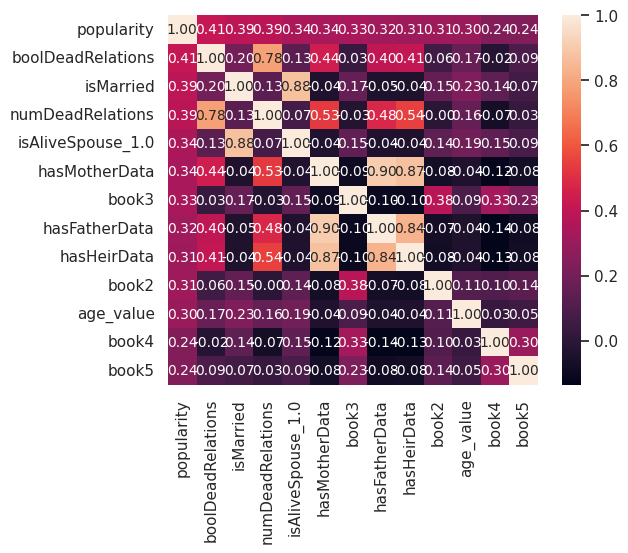

In [58]:
k = 13
cols = corrmat.nlargest(k, 'popularity')['popularity'].index
cm = np.corrcoef(data[cols].astype(float).values.T)
sns.set(font_scale=1.0)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values)
plt.show()

Видим, что сильная корреляция есть между преобразованными бинарными категориальными признаками, это происходит из-за отсутствия данных во многих столбцах в одной и той же строке. Чтобы это исправить я объединю 3 признака hasFatherData, hasMotherData, hasHeirData в 1 hasRelativeData

In [59]:
relatives = ['hasFatherData', 'hasMotherData', 'hasHeirData']
data['hasRelativeData'] = data[relatives].sum(axis=1)

In [60]:
data['hasRelativeData'] = [1 if x > 0 else 0 for x in data['hasRelativeData']]
data['hasRelativeData']

,hasRelativeData
S.No,
1,1
2,0
3,0
4,0
5,0
...,...
1553,0
1554,0
1555,0


In [61]:
data = data.drop(columns=['hasFatherData', 'hasMotherData', 'hasHeirData'])

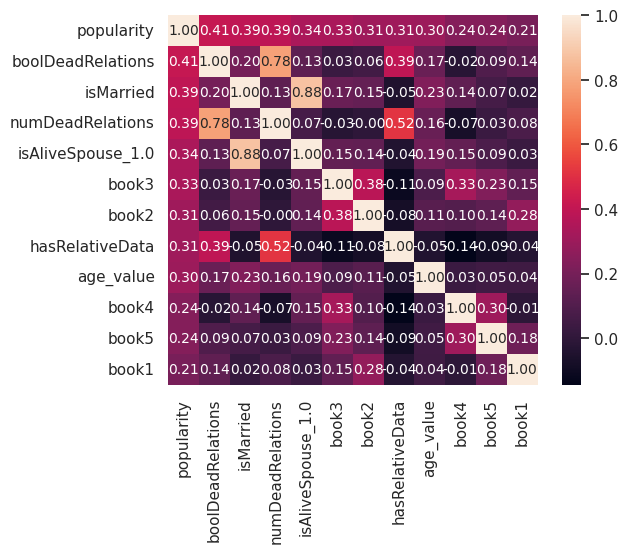

In [62]:
corrmat = data.corr(numeric_only=True)
k = 12
cols = corrmat.nlargest(k, 'popularity')['popularity'].index
cm = np.corrcoef(data[cols].astype(float).values.T)
sns.set(font_scale=1.0)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values)
plt.show()

При обучении модели я не буду учитывать признаки: IsMarried, boolDeadRelations, т.к. они сильно коррелируют с похожими им признаками.


**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

In [63]:
data.groupby('male', dropna = False)['isAlive'].mean()

,isAlive
male,
0,0.852433
1,0.727174


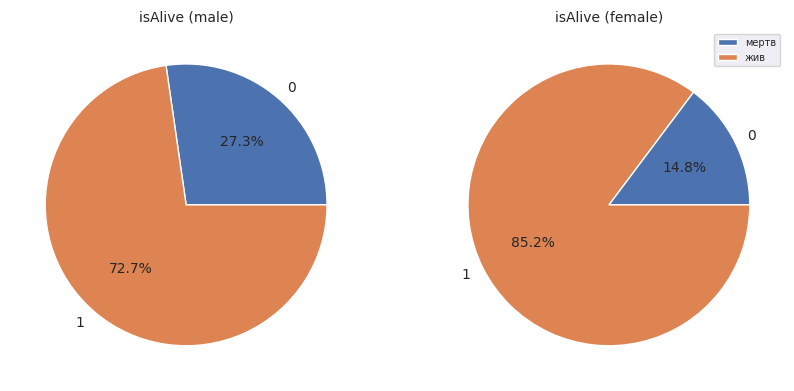

In [66]:
data_1 = data[data['male']== 1]['isAlive'].value_counts().sort_values()
data_2 = data[data['male']== 0]['isAlive'].value_counts().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (male)', fontsize=10)
ax2.set_title('isAlive (female)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('popularity', dropna = False)['isAlive'].mean()

,isAlive
popularity,
0.000000,0.865854
0.125302,0.919540
0.222429,0.938053
0.301756,0.941176
0.368806,0.777778
...,...
1.889798,0.000000
1.937612,1.000000
1.957282,1.000000


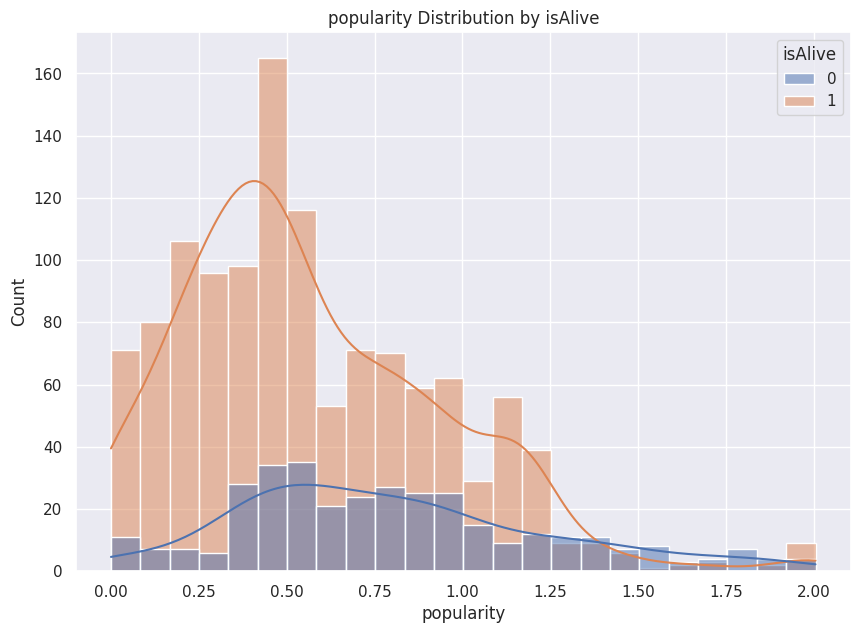

In [79]:
plt.figure(figsize=(10, 7))
sns.histplot(data=data, x='popularity', kde=True, hue='isAlive')
plt.title('popularity Distribution by isAlive')
plt.show()

In [ ]:
data.groupby('numDeadRelations', dropna = False)['isAlive'].mean()

,isAlive
numDeadRelations,
0,0.794355
1,0.625000
2,1.000000
3,0.250000
4,0.285714
5,0.400000
6,0.333333
7,0.142857
8,0.500000


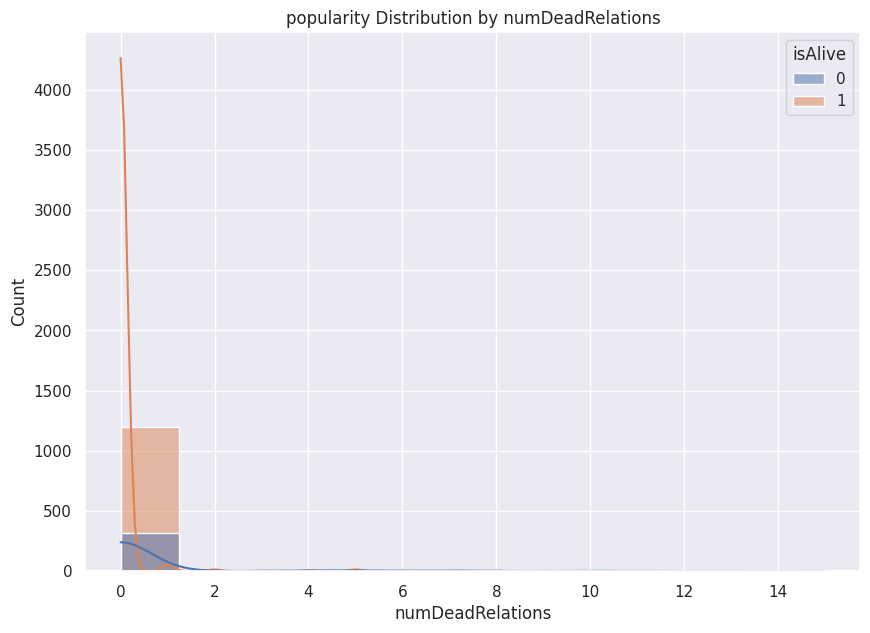

In [80]:
plt.figure(figsize=(10, 7))
sns.histplot(data=data, x='numDeadRelations', kde=True, hue='isAlive')
plt.title('popularity Distribution by numDeadRelations')
plt.show()

In [ ]:
data.groupby('hasRelativeData', dropna = False)['isAlive'].mean()

,isAlive
hasRelativeData,
0,0.785901
1,0.320000


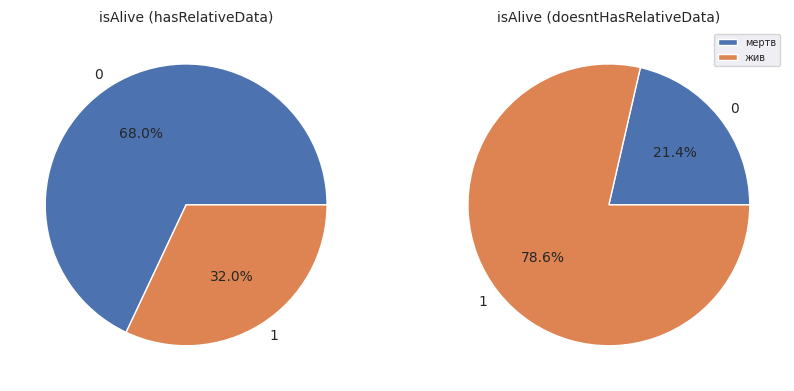

In [70]:
data_1 = data[data['hasRelativeData'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['hasRelativeData'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (hasRelativeData)', fontsize=10)
ax2.set_title('isAlive (doesntHasRelativeData)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('age_value', dropna = False)['isAlive'].mean()

,isAlive
age_value,
0.0,0.799219
2.0,0.000000
3.0,0.000000
6.0,0.800000
7.0,1.000000
...,...
85.0,1.000000
86.0,1.000000
94.0,1.000000


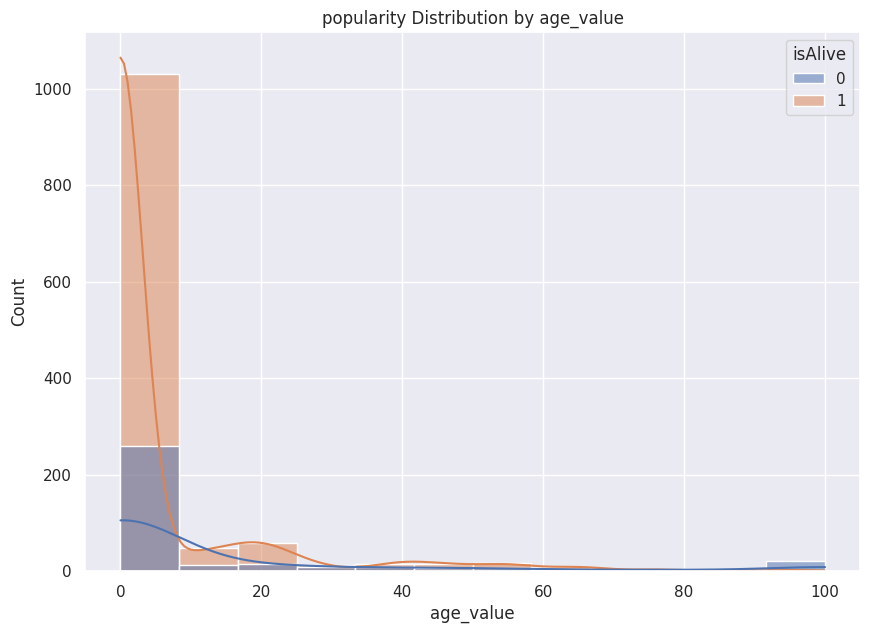

In [82]:
plt.figure(figsize=(10, 7))
sns.histplot(data=data, x='age_value', kde=True, hue='isAlive')
plt.title('popularity Distribution by age_value')
plt.show()

In [ ]:
data.groupby('isNoble', dropna = False)['isAlive'].mean()

,isAlive
isNoble,
0,0.800687
1,0.750000


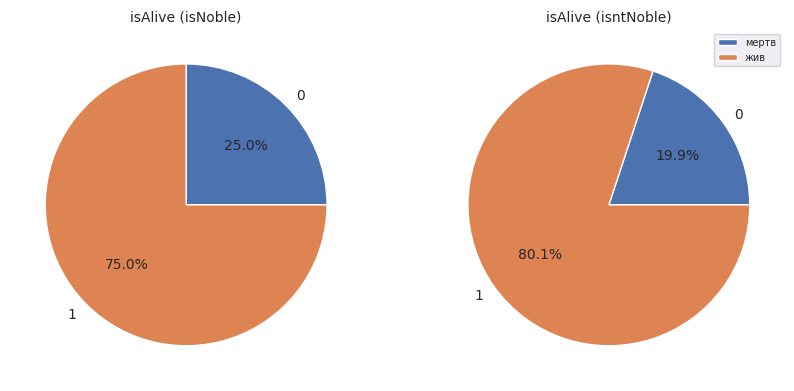

In [71]:
data_1 = data[data['isNoble'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['isNoble'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (isNoble)', fontsize=10)
ax2.set_title('isAlive (isntNoble)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('book1', dropna = False)['isAlive'].mean()

,isAlive
book1,
0,0.797166
1,0.662037


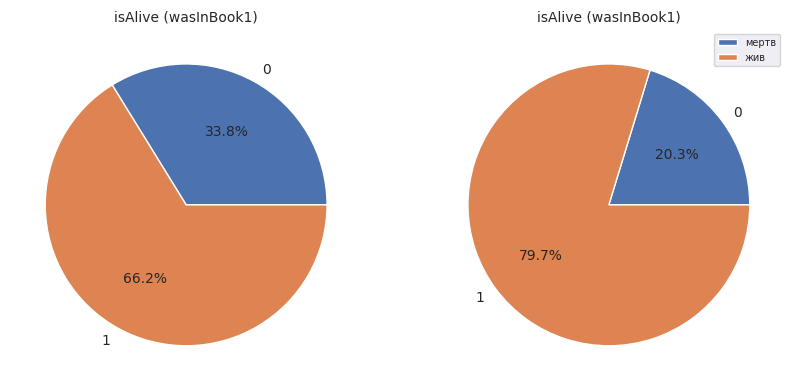

In [73]:
data_1 = data[data['book1'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['book1'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (wasInBook1)', fontsize=10)
ax2.set_title('isAlive (wasInBook1)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('book2', dropna = False)['isAlive'].mean()

,isAlive
book2,
0,0.794651
1,0.745098


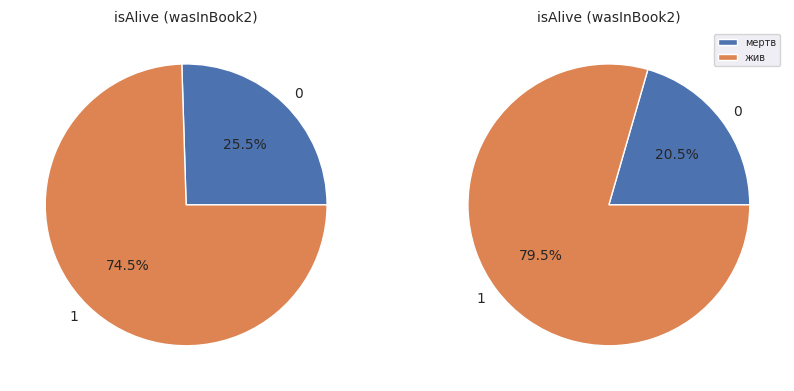

In [74]:
data_1 = data[data['book2'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['book2'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (wasInBook2)', fontsize=10)
ax2.set_title('isAlive (wasInBook2)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('book3', dropna = False)['isAlive'].mean()

,isAlive
book3,
0,0.771751
1,0.787202


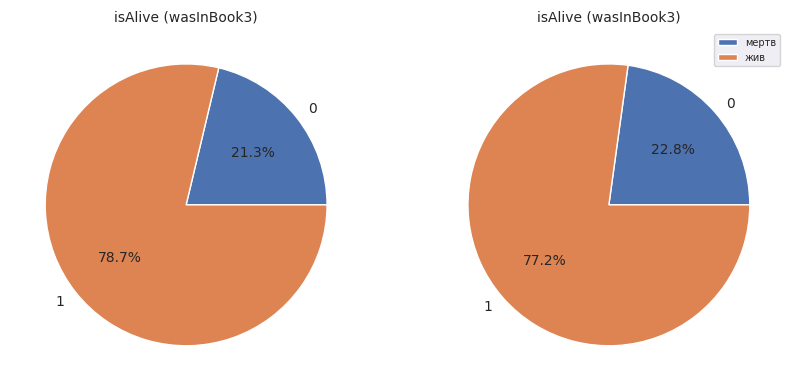

In [76]:
data_1 = data[data['book3'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['book3'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (wasInBook3)', fontsize=10)
ax2.set_title('isAlive (wasInBook3)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('book4', dropna = False)['isAlive'].mean()

,isAlive
book4,
0,0.64464
1,0.88242


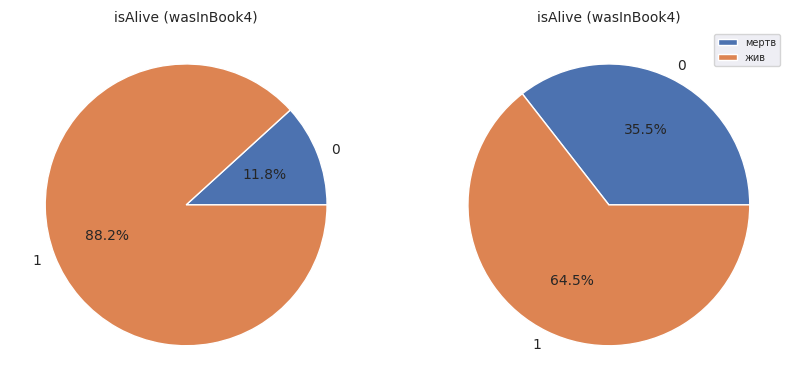

In [77]:
data_1 = data[data['book4'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['book4'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (wasInBook4)', fontsize=10)
ax2.set_title('isAlive (wasInBook4)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

In [ ]:
data.groupby('book5', dropna = False)['isAlive'].mean()

,isAlive
book5,
0,0.768936
1,0.797665


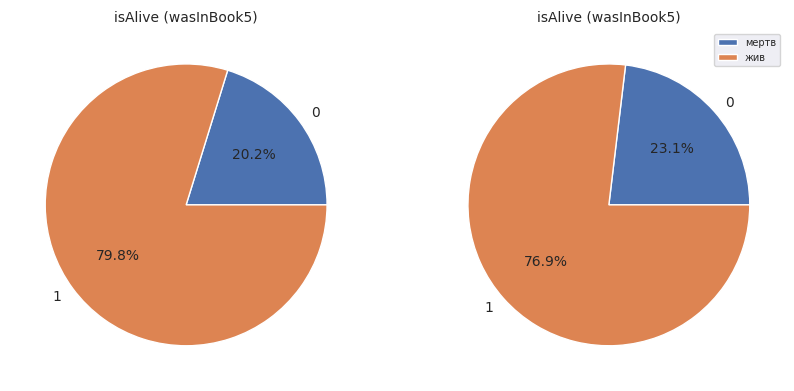

In [78]:
data_1 = data[data['book5'] == 1]['isAlive'].value_counts().sort_index()
data_2 = data[data['book5'] == 0]['isAlive'].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('isAlive (wasInBook5)', fontsize=10)
ax2.set_title('isAlive (wasInBook5)', fontsize=10)

plt.legend(['мертв', 'жив'], fontsize=7)

plt.show()

Каждый из перечисленных признаков влияет на целевую переменную, поэтому при обучении учту каждый

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [83]:
data.columns

Index(['name', 'title', 'male', 'culture', 'dateOfBirth', 'mother', 'father',
       'heir', 'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5',
       'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isMarried', 'isNoble',
       'age', 'numDeadRelations', 'popularity', 'isAlive', 'boolDeadRelations',
       'age_value', 'age_no_data', 'isAliveSpouse_0.0', 'isAliveSpouse_1.0',
       'isAliveSpouse_spouseAlive_no_data', 'culture_grouped_Dorne',
       'culture_grouped_Essos Nations', 'culture_grouped_Old Nations',
       'culture_grouped_Other Nations', 'culture_grouped_culture_no_data',
       'culture_grouped_the Iron Islands',
       'culture_grouped_the Isles and Rivers',
       'culture_grouped_the Mountain and the Vale',
       'culture_grouped_the North', 'culture_grouped_the Reach',
       'culture_grouped_the Rock', 'culture_grouped_the Stormlands',
       'title_grouped_Archmaester', 'title_grouped_King', 'title_grouped_Lady',
       'title_grouped_Lord', 'title

In [84]:
X = data[['male', 'dateOfBirth', 'book1', 'book2', 'book3', 'book4', 'book5',
       'isNoble', 'numDeadRelations', 'popularity',
       'age_value', 'age_no_data', 'isAliveSpouse_0.0', 'isAliveSpouse_1.0',
       'isAliveSpouse_spouseAlive_no_data', 'culture_grouped_Dorne',
       'culture_grouped_Essos Nations', 'culture_grouped_Old Nations',
       'culture_grouped_Other Nations', 'culture_grouped_culture_no_data',
       'culture_grouped_the Iron Islands',
       'culture_grouped_the Isles and Rivers',
       'culture_grouped_the Mountain and the Vale',
       'culture_grouped_the North', 'culture_grouped_the Reach',
       'culture_grouped_the Rock', 'culture_grouped_the Stormlands',
       'title_grouped_Archmaester', 'title_grouped_King', 'title_grouped_Lady',
       'title_grouped_Lord', 'title_grouped_Maester', 'title_grouped_Prince',
       'title_grouped_Septon', 'title_grouped_Ser', 'title_grouped_Winterfell',
       'title_grouped_rare', 'title_grouped_title_no_data',
       'house_grouped_Faith of the Seven', 'house_grouped_House Arryn',
       'house_grouped_House Botley', 'house_grouped_House Crakehall',
       'house_grouped_House Florent', 'house_grouped_House Frey',
       'house_grouped_House Greyjoy', 'house_grouped_House Hightower',
       'house_grouped_House Lannister', 'house_grouped_House Martell',
       'house_grouped_House Osgrey', 'house_grouped_House Stark',
       'house_grouped_House Targaryen', 'house_grouped_House Tyrell',
       "house_grouped_Night's Watch", 'house_grouped_house_no_data',
       'house_grouped_rare', 'hasRelativeData']]
y = data['isAlive'].values

**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [85]:
from sklearn.model_selection import train_test_split

In [86]:
# не забудьте в функции train_test_split задать параметр random_state,
# чтобы обеспечить повторяемость разбиения выборки на train и validation части.
# Это позволит сравнивать метрики моделей с различными методами подготовки признаков
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

Масштабируем числовые признаки: 'dateOfBirth', 'age_value', 'popularity', 'numDeadRelations'

In [87]:
from sklearn.preprocessing import StandardScaler

In [88]:
num_cols = ['dateOfBirth', 'age_value', 'popularity', 'numDeadRelations']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [89]:
from sklearn.linear_model import LogisticRegression

Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [90]:
# Шаг 1. создание модели
model = LogisticRegression()

# Шаг 2. обучение модели
model.fit(X_train, y_train)

# Шаг 3. Предсказание на тестовых данных
y_pred = model.predict(X_val)

## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [91]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [92]:
# Шаг 3. Предсказание на тестовых данных
y_pred = model.predict(X_val)
# ваш код здесь

# Шаг 4. Оценка предсказания по метрике accuracy
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy : %.4f" % accuracy)

Accuracy : 0.8237


Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [93]:
data_test =  pd.read_csv('/content/game_of_thrones_test.csv', index_col='S.No')

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

In [94]:
#Подсказка
data_test.loc[data_test['age']<0] # Находим данные с ошибками в дате рождения и возрасте

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity
S.No,,,,,,,,,,,,,,,,,,,,,
1685,Doreah,NaN,0,Lysene,278279.0,NaN,NaN,NaN,House Targaryen,NaN,...,1,NaN,NaN,NaN,NaN,0,0,-277980.0,0,0.110368
1869,Rhaego,NaN,0,NaN,298299.0,NaN,NaN,NaN,House Targaryen,NaN,...,0,NaN,NaN,NaN,NaN,0,0,-298001.0,6,0.167224


In [95]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:
data_test.loc[1685, 'dateOfBirth'] = 278.
# замены в строке 1685: dateOfBirth -> 278. и age -> 0.
data_test.loc[1685, 'age'] = 0.
# замены в строке 1869: dateOfBirth -> 299. и age -> 0.
data_test.loc[1869, 'dateOfBirth'] = 299.
data_test.loc[1869, 'age'] = 0.

Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

Обработка title

In [96]:
s_test = np.unique(data_test['title'].dropna().str.strip(), return_counts=True)
names, counts = s_test

s_new_test = [[names[0]], [counts[0]]]
title_grouped_inverted_test = {names[0]: names[0]}

for m in range(1, len(names)):
    base = s_new_test[0][-1]
    if counts[m] < 10 and names[m].startswith(base):
        s_new_test[1][-1] += counts[m]
        title_grouped_inverted_test[names[m]] = base
    else:
        s_new_test[0].append(names[m])
        s_new_test[1].append(counts[m])
        title_grouped_inverted_test[names[m]] = names[m]

s_new_test

[['Acorn Hall',
  'Andals',
  'Arbor',
  'Barrowton',
  'Bear Island',
  'Black Wind',
  'Blacktyde',
  'Bloodrider',
  'Brightwater',
  'Captain-General',
  'Castellan',
  'Casterly Rock',
  'Coldmoat',
  'Commander of the City Watch',
  'Darry',
  'Dreadfort',
  'Eyrie',
  'First Builder',
  'First Ranger',
  'Godswife',
  'Golden Storm',
  'Goldengrove',
  'Grand Maester',
  'Green Grace',
  'Greywater Watch',
  'Hand of the King',
  'Harlaw',
  'Harrenhal',
  'Haystack Hall',
  'High Septon',
  'Highgarden',
  'Hightower',
  'Horn Hill',
  'Iron Islands',
  'Karhold',
  'Keeper of the Gates of the Moon',
  'Khal',
  'King of Winter',
  'King-Beyond-the-Wall',
  'Knight',
  'Lady',
  'Lonely Light',
  'Longtable',
  'Lord',
  'Maester',
  'Magister',
  'Magnar of Thenn',
  'Master of Whisperers',
  'Master of coin',
  'Master of whisperers',
  'Nightsong',
  'Oakenshield',
  'Old Oak',
  'Old Wyk',
  'Prince',
  'QueenDowager Queen',
  'Raventree Hall',
  'Red Jester',
  'Riverrun',

In [97]:
s_new_test[0].append('rare')
s_new_test[1].append(0)

names, counts = s_new_test

for m in range(0, len(names)-1):
  if counts[m] < 10:
    counts[-1] += counts[m]
    names[m] = '-'
    counts[m] = 0

s_new_test

names_final = [x for x in names if x != '-']
counts_final = [x for x in counts if x != 0]

s_final_test = [names_final, counts_final]
s_final_test

[['Lord', 'Maester', 'Prince', 'Ser', 'rare'],
 [np.int64(19), np.int64(10), np.int64(14), np.int64(79), np.int64(99)]]

In [98]:
freq = set(names_final) - {'rare'}

title_final_test = {}
for orig, base in title_grouped_inverted_test.items():
    if base in freq:
        title_final_test[orig] = base
    else:
        title_final_test[orig] = 'rare'

title_final_test

{'Acorn Hall': 'rare',
 'Andals': 'rare',
 'Arbor': 'rare',
 'Barrowton': 'rare',
 'Bear Island': 'rare',
 'Black Wind': 'rare',
 'Blacktyde': 'rare',
 'Bloodrider': 'rare',
 'Brightwater': 'rare',
 'Captain-General': 'rare',
 'Castellan': 'rare',
 'Castellan of Harrenhal': 'rare',
 'Casterly Rock': 'rare',
 'Coldmoat': 'rare',
 'Commander of the City Watch': 'rare',
 'Darry': 'rare',
 'Dreadfort': 'rare',
 'Eyrie': 'rare',
 'First Builder': 'rare',
 'First Ranger': 'rare',
 'Godswife': 'rare',
 'Golden Storm': 'rare',
 'Goldengrove': 'rare',
 'Grand Maester': 'rare',
 'Green Grace': 'rare',
 'Greywater Watch': 'rare',
 'Hand of the King': 'rare',
 'Harlaw': 'rare',
 'Harrenhal': 'rare',
 'Haystack Hall': 'rare',
 'High Septon': 'rare',
 'Highgarden': 'rare',
 'Hightower': 'rare',
 'Horn Hill': 'rare',
 'Iron Islands': 'rare',
 'Karhold': 'rare',
 'Keeper of the Gates of the Moon': 'rare',
 'Khal': 'rare',
 'King of Winter': 'rare',
 'King-Beyond-the-Wall': 'rare',
 'Knight': 'rare',
 

In [99]:
data_test['title_grouped'] = data_test['title'].map(title_final_test)
data_test['title_grouped'] = ['title_no_data' if pd.isna(x) else x for x in data_test['title_grouped']]
data_test['title_grouped']

,title_grouped
S.No,
1558,title_no_data
1559,title_no_data
1560,title_no_data
1561,Ser
1562,title_no_data
...,...
1942,title_no_data
1943,title_no_data
1944,title_no_data


Обработка house

In [100]:
s_test = np.unique(data_test['house'].dropna().str.strip(), return_counts=True)

names, counts = s_test
names, counts = list(names), list(counts)

names.append('rare')
counts.append(0)

for m in range(0, len(names) - 1):
  if counts[m] < 10:
    names[m] = '-'
    counts[-1] += counts[m]
    counts[m] = 0

names_final = [x for x in names if x != '-']
counts_final = [x for x in counts if x != 0]

s_new_test = [names_final, counts_final]
s_new_test

[['House Greyjoy',
  'House Lannister',
  'House Martell',
  'House Stark',
  'House Targaryen',
  "Night's Watch",
  'rare'],
 [np.int64(11),
  np.int64(13),
  np.int64(18),
  np.int64(16),
  np.int64(22),
  np.int64(17),
  np.int64(246)]]

Теперь на основе полученного s_new создадим словарь

In [101]:
freq = set(names_final) - {'rare'}

all_houses_test = data_test['house'].dropna().unique()

house_final_test = {h: (h if h in freq else 'rare') for h in all_houses_test}

house_final_test

{'House Blackwood': 'rare',
 "R'hllor": 'rare',
 'Brotherhood without banners': 'rare',
 'House Trant': 'rare',
 'House Frey': 'rare',
 'House Bracken': 'rare',
 'House Targaryen': 'House Targaryen',
 "House Baratheon of King's Landing": 'rare',
 'House Arryn': 'rare',
 'House Whent': 'rare',
 'House Stark': 'House Stark',
 'House Martell': 'House Martell',
 'House Royce of the Gates of the Moon': 'rare',
 'House Greyjoy': 'House Greyjoy',
 'House Redwyne': 'rare',
 'House Redfort': 'rare',
 'House Kettleblack': 'rare',
 'House Baratheon': 'rare',
 'House Yarwyck': 'rare',
 'House Hightower': 'rare',
 'House Baratheon of Dragonstone': 'rare',
 'House Caron': 'rare',
 'House Payne': 'rare',
 'House Greenfield': 'rare',
 'House Clegane': 'rare',
 'Undying Ones': 'rare',
 'House Lannister': 'House Lannister',
 "Night's Watch": "Night's Watch",
 'House Stonehouse': 'rare',
 'House Bolton of the Dreadfort': 'rare',
 'House Tarly': 'rare',
 'House Fossoway of New Barrel': 'rare',
 'House Dar

In [102]:
data_test['house_grouped'] = data_test['house'].map(house_final_test)
data_test['house_grouped'] = ['house_no_data' if pd.isna(x) else x for x in data_test['house_grouped']]
data_test['house_grouped']

,house_grouped
S.No,
1558,rare
1559,rare
1560,rare
1561,rare
1562,rare
...,...
1942,House Stark
1943,rare
1944,house_no_data


Обработка isAliveSpouse


In [103]:
data_test['isAliveSpouse'] = ['spouseAlive_no_data' if pd.isna(x) else x for x in data_test['isAliveSpouse']]

Обработка isAliveMother

In [104]:
data_test['isAliveMother'] = ['motherAlive_no_data' if pd.isna(x) else x for x in data_test['isAliveMother']]
data_test['hasMotherData'] = (data_test['isAliveMother'] != 'motherAlive_no_data').astype(int)

In [105]:
data_test['hasMotherData']

,hasMotherData
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


Обработка isAliveFather


In [106]:
data_test['isAliveFather'] = ['fatherAlive_no_data' if pd.isna(x) else x for x in data_test['isAliveFather']]

In [107]:
# т.к. большинство данных не дано, то свернем до бинарного признака: есть данные и нет данных
data_test['hasFatherData'] = (data_test['isAliveFather'] != 'fatherAlive_no_data').astype(int)
data_test['hasFatherData']

,hasFatherData
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


Обработка isAliveHeir

In [108]:
data_test['isAliveHeir'] = ['heirAlive_no_data' if pd.isna(x) else x for x in data_test['isAliveHeir']] # убираем Nan по аналогии с culture

In [109]:
# т.к. большинство данных не дано, то свернем до бинарного признака: есть данные и нет данных
data_test['hasHeirData'] = (data_test['isAliveHeir'] != 'heirAlive_no_data').astype(int)

In [110]:
data_test['hasHeirData']

,hasHeirData
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


Обработка culture

In [111]:
data_test['culture'].value_counts(dropna=False)

,count
culture,
NaN,200
Northmen,30
Ironborn,21
Valyrian,15
Dornishmen,11
Valemen,9
Rivermen,9
Westeros,9
Ghiscari,8


In [112]:
cultures_grouped_test = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

In [113]:
cultures_grouped_inverted_test = {}

for k in cultures_grouped_test.keys():
  for v in cultures_grouped_test[k]:
    cultures_grouped_inverted_test.update({v:k})

cultures_grouped_inverted_test

{'valyrian': 'Old Nations',
 'first men': 'Old Nations',
 'andal': 'Old Nations',
 'andals': 'Old Nations',
 'rhoynar': 'Old Nations',
 'northmen': 'the North',
 'northern mountain clans': 'the North',
 'crannogmen': 'the North',
 'ironborn': 'the Iron Islands',
 'ironmen': 'the Iron Islands',
 'valemen': 'the Mountain and the Vale',
 'vale': 'the Mountain and the Vale',
 'vale mountain clans': 'the Mountain and the Vale',
 'sistermen': 'the Mountain and the Vale',
 'riverlands': 'the Isles and Rivers',
 'rivermen': 'the Isles and Rivers',
 'westerman': 'the Rock',
 'westermen': 'the Rock',
 'westerlands': 'the Rock',
 'stormlander': 'the Stormlands',
 'stormlands': 'the Stormlands',
 'reach': 'the Reach',
 'reachmen': 'the Reach',
 'the reach': 'the Reach',
 'dornish': 'Dorne',
 'dornishmen': 'Dorne',
 'dorne': 'Dorne',
 'astapor': 'Essos Nations',
 'astapori': 'Essos Nations',
 'braavosi': 'Essos Nations',
 'braavos': 'Essos Nations',
 'tyroshi': 'Essos Nations',
 'lysene': 'Essos Na

In [114]:
data_test['culture_grouped'] = data_test['culture'].str.lower().map(cultures_grouped_inverted_test)

In [115]:
data_test['culture_grouped'] = ['culture_no_data' if pd.isna(x) else x for x in data_test['culture_grouped']]

In [116]:
data_test['culture_grouped']

,culture_grouped
S.No,
1558,culture_no_data
1559,Essos Nations
1560,culture_no_data
1561,culture_no_data
1562,the Isles and Rivers
...,...
1942,Other Nations
1943,culture_no_data
1944,culture_no_data


Перевод категориальных признаков в числа с помощью One-hot Encoding

In [117]:
data_test['isAliveSpouse'] = data_test['isAliveSpouse'].astype(str)
categorical_columns_test = ['isAliveSpouse', 'culture_grouped', 'title_grouped', 'house_grouped']

In [118]:
data_test.columns

Index(['name', 'title', 'male', 'culture', 'dateOfBirth', 'mother', 'father',
       'heir', 'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5',
       'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse',
       'isMarried', 'isNoble', 'age', 'numDeadRelations', 'popularity',
       'title_grouped', 'house_grouped', 'hasMotherData', 'hasFatherData',
       'hasHeirData', 'culture_grouped'],
      dtype='object')

In [122]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='if_binary', sparse_output=False)
new_category_columns_test = ohe.transform(data_test[categorical_columns_test])

KeyError: "None of [Index(['isAliveSpouse', 'culture_grouped', 'title_grouped', 'house_grouped'], dtype='object')] are in the [columns]"

In [119]:
new_category_columns_test

NameError: name 'new_category_columns_test' is not defined

In [ ]:
ohe.get_feature_names_out()

array(['isAliveSpouse_0.0', 'isAliveSpouse_1.0',
       'isAliveSpouse_spouseAlive_no_data', 'culture_grouped_Dorne',
       'culture_grouped_Essos Nations', 'culture_grouped_Old Nations',
       'culture_grouped_Other Nations', 'culture_grouped_culture_no_data',
       'culture_grouped_the Iron Islands',
       'culture_grouped_the Isles and Rivers',
       'culture_grouped_the Mountain and the Vale',
       'culture_grouped_the North', 'culture_grouped_the Reach',
       'culture_grouped_the Rock', 'culture_grouped_the Stormlands',
       'title_grouped_Lord', 'title_grouped_Maester',
       'title_grouped_Prince', 'title_grouped_Ser', 'title_grouped_rare',
       'title_grouped_title_no_data', 'house_grouped_House Greyjoy',
       'house_grouped_House Lannister', 'house_grouped_House Martell',
       'house_grouped_House Stark', 'house_grouped_House Targaryen',
       "house_grouped_Night's Watch", 'house_grouped_house_no_data',
       'house_grouped_rare'], dtype=object)

In [ ]:
new_train_columns_test = pd.DataFrame(new_category_columns_test, columns=ohe.get_feature_names_out(), index=data_test.index)
data_test = data_test.drop(columns=categorical_columns_test)
data_test = pd.concat([data_test, new_train_columns_test], axis=1)
data_test.head()

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,title_grouped_rare,title_grouped_title_no_data,house_grouped_House Greyjoy,house_grouped_House Lannister,house_grouped_House Martell,house_grouped_House Stark,house_grouped_House Targaryen,house_grouped_Night's Watch,house_grouped_house_no_data,house_grouped_rare
S.No,,,,,,,,,,,,,,,,,,,,,
1558,Melissa Blackwood,NaN,0,NaN,156.0,NaN,NaN,NaN,House Blackwood,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1559,Melisandre,NaN,0,Asshai,NaN,NaN,NaN,NaN,R'hllor,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1560,Merrit,NaN,0,NaN,NaN,NaN,NaN,NaN,Brotherhood without banners,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1561,Meryn Trant,Ser,1,NaN,NaN,NaN,NaN,NaN,House Trant,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1562,Merrett Frey,NaN,1,Riverlands,262.0,NaN,NaN,NaN,House Frey,Mariya Darry,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 389 entries, 1558 to 1946
Data columns (total 55 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   name                                       389 non-null    object 
 1   title                                      221 non-null    object 
 2   male                                       389 non-null    int64  
 3   culture                                    189 non-null    object 
 4   dateOfBirth                                154 non-null    float64
 5   mother                                     3 non-null      object 
 6   father                                     4 non-null      object 
 7   heir                                       2 non-null      object 
 8   house                                      343 non-null    object 
 9   spouse                                     76 non-null     object 
 10  book1                      

Категориальные признаки обработаны полностью, количественные остались


In [ ]:
median_dateOfBirth_test = np.quantile(data_test['dateOfBirth'].dropna().values, q=0.5)
data_test['dateOfBirth'] = data_test['dateOfBirth'].fillna(median_dateOfBirth_test)
data_test['dateOfBirth'].isna().sum()

np.int64(0)

In [ ]:
data_test['age_value'] = [0 if np.isnan(x) else x for x in data_test['age']]
data_test['age_no_data'] = [1 if np.isnan(x) else 0 for x in data_test['age']]

In [ ]:
data_test['age_value']

,age_value
S.No,
1558,100.0
1559,0.0
1560,0.0
1561,0.0
1562,38.0
...,...
1942,0.0
1943,0.0
1944,0.0


In [ ]:
data_test['age']

,age
S.No,
1558,100.0
1559,NaN
1560,NaN
1561,NaN
1562,38.0
...,...
1942,NaN
1943,NaN
1944,NaN


In [ ]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 389 entries, 1558 to 1946
Data columns (total 57 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   name                                       389 non-null    object 
 1   title                                      221 non-null    object 
 2   male                                       389 non-null    int64  
 3   culture                                    189 non-null    object 
 4   dateOfBirth                                389 non-null    float64
 5   mother                                     3 non-null      object 
 6   father                                     4 non-null      object 
 7   heir                                       2 non-null      object 
 8   house                                      343 non-null    object 
 9   spouse                                     76 non-null     object 
 10  book1                      

### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [ ]:
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

Downloading...
From: https://drive.google.com/uc?id=1M14conWjAW2QLoyCXbHEAy8bql2f99eF
To: /content/submission.csv
100% 2.74k/2.74k [00:00<00:00, 9.42MB/s]


In [ ]:
submission = pd.read_csv("/content/submission.csv", index_col='S.No')

In [ ]:
submission

,isAlive
S.No,
1558,0
1559,0
1560,0
1561,0
1562,0
...,...
1942,0
1943,0
1944,0


Как сохранить измененный Pandas DataFrame в csv файл:

In [ ]:
submission.to_csv("/content/new_submission.csv", index=False)